# IDC409 Project - House Price Prediction

Predicts house price from area, location, rooms, amenities and property details, using the **Kaggle "India House Price Prediction" dataset** (250,000 listings, 42 cities).

**Project-slide checklist covered in this notebook**

| Slide requirement | Where |
|---|---|
| numpy / pandas to store data | §1 |
| Database: read, write, modify | §2b (SQLite) |
| EDA: price distribution, location effects, price per sq-ft, outliers, area analysis | §3 |
| Features understood + reduced | §4 |
| Baseline + ML models (Linear, Ridge, Lasso, Decision Tree, Random Forest, Gradient Boosting) | §5 |
| Metrics: MAE, RMSE, R², error in rupees and % | §5 |
| Extensions: city-wise models + price-category classification | §6 |
| Prediction function for a new house | §7 |
| GitHub-ready (README, requirements) | repo files |

In [2]:
import os, re, glob, zipfile, sqlite3, warnings, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

try:
    import tabulate                                   # needed for DataFrame.to_markdown()
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tabulate"])

warnings.filterwarnings("ignore")

def _fmt(x):
    return f"{x:,.2f}" if (abs(x) >= 0.01 or x == 0) else f"{x:.2e}"
pd.set_option("display.float_format", _fmt)
pd.set_option("display.max_columns", 60)
sns.set_style("whitegrid")

SEED = 42                    # one seed -> every shuffle / split / model is reproducible
CURRENT_YEAR = 2025
LAKH = 100_000               # 1 lakh = 100,000 rupees
np.random.seed(SEED)


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


## 1. Data
The notebook now uses the **real Kaggle file** (`india_housing_prices.csv`, shipped inside `archive.zip`) instead of the synthetic generator.
Put `archive.zip` next to this notebook (on Google Colab it will ask you to upload it).

| Column | Meaning |
|---|---|
| `State`, `City`, `Locality` | location (Locality is an anonymous label, `Locality_1 … Locality_500`) |
| `Property_Type` | Apartment / Independent House / Villa |
| `BHK`, `Size_in_SqFt` | bedrooms, built-up area |
| `Price_in_Lakhs` | **target** (1 lakh = ₹100,000) |
| `Price_per_SqFt` | price ÷ size, in lakhs/sq-ft — **derived from the target, so it is never used as a feature** |
| `Year_Built`, `Age_of_Property` | construction year / age (the same information twice) |
| `Furnished_Status`, `Floor_No`, `Total_Floors`, `Facing`, `Parking_Space`, `Security`, `Amenities` | property details |
| `Nearby_Schools`, `Nearby_Hospitals`, `Public_Transport_Accessibility` | neighbourhood |
| `Owner_Type`, `Availability_Status` | seller / construction status |

In [3]:
DATA_FILE = "india_housing_prices.csv"

def find_dataset():
    hits = [p for p in ["data/" + DATA_FILE, DATA_FILE] if os.path.exists(p)]
    hits += glob.glob("**/" + DATA_FILE, recursive=True)
    if hits:
        return hits[0]
    for z in glob.glob("*.zip") + glob.glob("data/*.zip"):          # unzip archive.zip if needed
        with zipfile.ZipFile(z) as zf:
            if DATA_FILE in zf.namelist():
                os.makedirs("data", exist_ok=True)
                zf.extract(DATA_FILE, "data")
                return os.path.join("data", DATA_FILE)
    return None

DATA_PATH = find_dataset()
if DATA_PATH is None:
    try:                                                              # Google Colab: upload archive.zip
        from google.colab import files
        files.upload()
        DATA_PATH = find_dataset()
    except ImportError:
        pass
assert DATA_PATH, "Place archive.zip (or india_housing_prices.csv) next to this notebook."
print("Using:", DATA_PATH)

Using: data/india_housing_prices.csv


**Randomising the observations.** The file is sorted by `ID`. We shuffle every row once (seeded, so it is reproducible) and later use shuffled train/test splits and shuffled cross-validation folds, so no ordering effect can leak into the results.

In [6]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print("Row order as downloaded  (first 8 IDs):", df_raw["ID"].head(8).tolist())

df_raw = df_raw.sample(frac=1, random_state=SEED).reset_index(drop=True)     # <- randomise observations
print("Row order after shuffle  (first 8 IDs):", df_raw["ID"].head(8).tolist())
df_raw.head()

Loaded 250,000 rows x 23 columns
Row order as downloaded  (first 8 IDs): [1, 2, 3, 4, 5, 6, 7, 8]
Row order after shuffle  (first 8 IDs): [38684, 64940, 3955, 120375, 172862, 149304, 111627, 164554]


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,38684,Haryana,Gurgaon,Locality_123,Independent House,4,692,256.62,0.37,2022,Semi-furnished,15,24,3,6,6,Medium,Yes,No,"Playground, Pool",South,Builder,Ready_to_Move
1,64940,Andhra Pradesh,Vishakhapatnam,Locality_74,Apartment,2,3094,86.04,0.03,2015,Furnished,3,18,10,3,8,Medium,No,No,"Gym, Clubhouse, Pool, Garden",South,Builder,Under_Construction
2,3955,Madhya Pradesh,Bhopal,Locality_486,Apartment,3,4993,237.86,0.05,1995,Unfurnished,19,27,30,10,1,High,No,No,"Gym, Pool, Playground, Clubhouse, Garden",West,Owner,Ready_to_Move
3,120375,Punjab,Ludhiana,Locality_13,Villa,1,2461,339.41,0.14,2018,Semi-furnished,20,14,7,10,5,Low,Yes,No,"Pool, Gym",South,Owner,Under_Construction
4,172862,Haryana,Faridabad,Locality_22,Independent House,2,4535,124.99,0.03,1991,Semi-furnished,25,5,34,5,9,Medium,No,Yes,Pool,South,Builder,Under_Construction


In [7]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,"250,000.00","125,000.50","72,168.93",1.00,"62,500.75","125,000.50","187,500.25","250,000.00"
BHK,"250,000.00",3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,"250,000.00","2,749.81","1,300.61",500.00,"1,623.00","2,747.00","3,874.00","5,000.00"
Price_in_Lakhs,"250,000.00",254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,"250,000.00",0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,"250,000.00","2,006.52",9.81,"1,990.00","1,998.00","2,007.00","2,015.00","2,023.00"
Floor_No,"250,000.00",14.97,8.95,0.00,7.00,15.00,23.00,30.00
Total_Floors,"250,000.00",15.50,8.67,1.00,8.00,15.00,23.00,30.00
Age_of_Property,"250,000.00",18.48,9.81,2.00,10.00,18.00,27.00,35.00
Nearby_Schools,"250,000.00",5.50,2.88,1.00,3.00,5.00,8.00,10.00


## 2. Data Cleaning
Steps: validate → remove duplicates → impute missing values (median / mode) → fix impossible values → cap outliers by IQR (**price is checked per city**, because price levels differ by city) → convert to rupees → derive features.

Two things the file needs that a clean-looking dataset hides (shown in the next cell):
* `Floor_No > Total_Floors` in ~46% of rows (a house cannot be on floor 22 of a 1-floor building).
* `Price_per_SqFt` is just `Price ÷ Size` → **target leakage**; we drop it and recompute a rupee version for EDA only.

In [8]:
AMENITY_LIST = ["Clubhouse", "Garden", "Gym", "Playground", "Pool"]


def missing_value_report(df: pd.DataFrame) -> pd.DataFrame:
    miss = df.isna().sum()
    miss = miss[miss > 0]
    pct = (miss / len(df) * 100).round(2)
    return pd.DataFrame({"missing_count": miss, "missing_pct": pct}).sort_values("missing_count", ascending=False)


def detect_outliers_iqr(df, cols) -> dict:
    """Global IQR outlier detection."""
    report = {}
    for col in cols:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (df[col] < low) | (df[col] > high)
        report[col] = {"lower_bound": float(low), "upper_bound": float(high), "n_outliers": int(mask.sum())}
    return report


def detect_outliers_iqr_grouped(df, col, group_col) -> pd.DataFrame:
    """Group-wise IQR bounds (price is judged against its own city, not against the whole country)."""
    rows = []
    for grp, sub in df.groupby(group_col):
        q1, q3 = sub[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (sub[col] < low) | (sub[col] > high)
        rows.append({group_col: grp, "lower_bound": float(low), "upper_bound": float(high), "n_outliers": int(mask.sum())})
    return pd.DataFrame(rows).set_index(group_col)


def add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:
    """Features derived ONLY from inputs (never from the price) - shared by training and prediction."""
    df = df.copy()
    am = df["Amenities"].fillna("").astype(str)
    for a in AMENITY_LIST:
        df[f"Has_{a}"] = am.str.contains(a, regex=False).astype(int)
    df["Amenity_Count"] = df[[f"Has_{a}" for a in AMENITY_LIST]].sum(axis=1)
    df["Size_per_BHK"] = (df["Size_in_SqFt"] / df["BHK"].clip(lower=1)).round(1)
    df["Floor_Ratio"] = (df["Floor_No"] / df["Total_Floors"].clip(lower=1)).round(3)
    return df


def clean_data(df: pd.DataFrame):
    """Returns (cleaned_df, log_of_actions, outlier_report_before_capping)."""
    log, df = [], df.copy()
    n0 = len(df)

    # tidy text
    for c in df.columns[df.dtypes.map(lambda t: not pd.api.types.is_numeric_dtype(t))]:
        df[c] = df[c].str.strip()

    # duplicates (ignoring the ID column)
    cols_wo_id = [c for c in df.columns if c != "ID"]
    dup = int(df.duplicated(subset=cols_wo_id).sum())
    df = df.drop_duplicates(subset=cols_wo_id).reset_index(drop=True)
    log.append(f"Removed {dup} duplicate rows ({n0:,} -> {len(df):,} rows).")

    # missing values
    num_cols = [c for c in df.select_dtypes("number").columns if c != "ID"]
    cat_cols = [c for c in df.columns if c not in num_cols and c != "ID"]
    n_imputed = 0
    for col in num_cols:
        k = int(df[col].isna().sum())
        if k:
            m = df[col].median(); df[col] = df[col].fillna(m); n_imputed += k
            log.append(f"Imputed {k} missing '{col}' values with the median ({m:.1f}).")
    for col in cat_cols:
        k = int(df[col].isna().sum())
        if k:
            m = df[col].mode()[0]; df[col] = df[col].fillna(m); n_imputed += k
            log.append(f"Imputed {k} missing '{col}' values with the mode ('{m}').")
    if not n_imputed:
        log.append("No missing values found - nothing to impute.")

    # impossible values: floor number above the building's number of floors -> the two values were entered the wrong way round
    bad = df["Floor_No"] > df["Total_Floors"]
    n_bad = int(bad.sum())
    if n_bad:
        fl, tf = df.loc[bad, "Floor_No"].copy(), df.loc[bad, "Total_Floors"].copy()
        df.loc[bad, "Floor_No"], df.loc[bad, "Total_Floors"] = tf, fl
        log.append(f"Fixed {n_bad:,} rows ({n_bad/len(df):.1%}) where Floor_No > Total_Floors by swapping the two values.")
    mism = int((df["Year_Built"] + df["Age_of_Property"] != CURRENT_YEAR).sum())
    log.append(f"Year_Built + Age_of_Property == {CURRENT_YEAR} in all but {mism} rows -> the two columns are redundant (see §4).")

    # Yes/No -> 1/0
    for c in ["Parking_Space", "Security"]:
        df[c] = (df[c].str.lower() == "yes").astype(int)

    # outliers: price per city, size globally
    price_bounds = detect_outliers_iqr_grouped(df, "Price_in_Lakhs", "City")
    n_price_out = int(price_bounds["n_outliers"].sum())
    if n_price_out:
        for city, row in price_bounds.iterrows():
            m = df["City"] == city
            df.loc[m, "Price_in_Lakhs"] = df.loc[m, "Price_in_Lakhs"].clip(row["lower_bound"], row["upper_bound"])
        log.append(f"Capped {n_price_out} price outliers using a separate IQR range per city.")
    else:
        log.append("Price outliers (IQR, checked separately for each of the 42 cities): none found.")
    size_b = detect_outliers_iqr(df, ["Size_in_SqFt"])["Size_in_SqFt"]
    if size_b["n_outliers"]:
        df["Size_in_SqFt"] = df["Size_in_SqFt"].clip(size_b["lower_bound"], size_b["upper_bound"])
        log.append(f"Capped {size_b['n_outliers']} 'Size_in_SqFt' outliers to [{size_b['lower_bound']:.0f}, {size_b['upper_bound']:.0f}].")
    else:
        log.append("Size_in_SqFt outliers (global IQR): none found.")

    # rupees + derived features
    df["Price_INR"] = (df["Price_in_Lakhs"] * LAKH).round(0)
    df["Price_per_SqFt_INR"] = (df["Price_INR"] / df["Size_in_SqFt"]).round(1)     # EDA only (derived from the target!)
    df = df.drop(columns=["Price_per_SqFt"])                                          # original is in lakhs/sqft, 2-decimal rounded
    log.append("Dropped the original 'Price_per_SqFt' (leaks the target); recomputed 'Price_per_SqFt_INR' for EDA only.")
    df = add_engineered_features(df)
    log.append("Derived: Amenity_Count, Has_<amenity> flags, Size_per_BHK, Floor_Ratio.")

    outlier_report_before = {"price_by_city": price_bounds, "size": size_b}
    return df, log, outlier_report_before


def save_cleaned(df, csv_path="outputs/cleaned_house_data.csv", db_path="outputs/house_data.db"):
    os.makedirs(os.path.dirname(csv_path), exist_ok=True)
    df.to_csv(csv_path, index=False)
    conn = sqlite3.connect(db_path)
    df.to_sql("cleaned_houses", conn, if_exists="replace", index=False)
    conn.execute("CREATE INDEX IF NOT EXISTS idx_city ON cleaned_houses(City)")
    conn.commit(); conn.close()


def write_cleaning_report(df_raw, log, outlier_report, path="outputs/data_cleaning_report.md"):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    miss = missing_value_report(df_raw)
    L = ["# Data Cleaning Report", "",
         f"Raw dataset: **{len(df_raw):,} rows**, **{df_raw.shape[1]} columns**.", "",
         "## 1. Missing values found (before cleaning)", ""]
    L.append(miss.to_markdown() if len(miss) else "No missing values found.")
    L += ["", "## 2. Outliers detected (IQR method, before capping)", "",
          "'Price_in_Lakhs' is checked **per city**; 'Size_in_SqFt' is checked globally.", "",
          "**Price outliers by city** (only cities with at least one outlier are listed):", ""]
    pb = outlier_report["price_by_city"]
    L.append(pb[pb["n_outliers"] > 0].to_markdown() if (pb["n_outliers"] > 0).any() else f"None of the {len(pb)} cities has a price outlier.")
    b = outlier_report["size"]
    L += ["", f"**Size_in_SqFt** (global): {b['n_outliers']} outlier(s) outside [{b['lower_bound']:.0f}, {b['upper_bound']:.0f}]",
          "", "## 3. Cleaning actions taken", ""]
    L += [f"- {l}" for l in log]
    with open(path, "w") as f:
        f.write("\n".join(L))
    return path

In [9]:
miss = missing_value_report(df_raw)
print("Missing values:", "none in any column" if miss.empty else "")
if not miss.empty:
    display(miss)

print("Correlation of Price_per_SqFt with (Price / Size):",
      round(np.corrcoef(df_raw["Price_in_Lakhs"] / df_raw["Size_in_SqFt"], df_raw["Price_per_SqFt"])[0, 1], 4),
      " -> it is the target in disguise (leakage)\n")

checks = pd.Series({
    "rows": len(df_raw),
    "duplicate rows (ignoring ID)": int(df_raw.duplicated(subset=[c for c in df_raw.columns if c != "ID"]).sum()),
    "Floor_No > Total_Floors (impossible)": int((df_raw["Floor_No"] > df_raw["Total_Floors"]).sum()),
    f"Year_Built + Age_of_Property != {CURRENT_YEAR}": int((df_raw["Year_Built"] + df_raw["Age_of_Property"] != CURRENT_YEAR).sum()),
    "cities that belong to >1 state": int((df_raw.groupby("City")["State"].nunique() > 1).sum()),
})
checks.to_frame("count")

Missing values: none in any column
Correlation of Price_per_SqFt with (Price / Size): 0.9998  -> it is the target in disguise (leakage)



,count
rows,250000
duplicate rows (ignoring ID),0
Floor_No > Total_Floors (impossible),116304
Year_Built + Age_of_Property != 2025,0
cities that belong to >1 state,0


In [10]:
df_cleaned, cleaning_log, outlier_report = clean_data(df_raw)
for line in cleaning_log:
    print("-", line)

os.makedirs("outputs", exist_ok=True)
save_cleaned(df_cleaned, "outputs/cleaned_house_data.csv", "outputs/house_data.db")
write_cleaning_report(df_raw, cleaning_log, outlier_report, "outputs/data_cleaning_report.md")
print(f"\nCleaned shape: {df_cleaned.shape}  ->  saved to outputs/ (CSV + SQLite + cleaning report)")
df_cleaned.head()

- Removed 0 duplicate rows (250,000 -> 250,000 rows).
- No missing values found - nothing to impute.
- Fixed 116,304 rows (46.5%) where Floor_No > Total_Floors by swapping the two values.
- Year_Built + Age_of_Property == 2025 in all but 0 rows -> the two columns are redundant (see §4).
- Price outliers (IQR, checked separately for each of the 42 cities): none found.
- Size_in_SqFt outliers (global IQR): none found.
- Dropped the original 'Price_per_SqFt' (leaks the target); recomputed 'Price_per_SqFt_INR' for EDA only.
- Derived: Amenity_Count, Has_<amenity> flags, Size_per_BHK, Floor_Ratio.

Cleaned shape: (250000, 32)  ->  saved to outputs/ (CSV + SQLite + cleaning report)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status,Price_INR,Price_per_SqFt_INR,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground,Has_Pool,Amenity_Count,Size_per_BHK,Floor_Ratio
0,38684,Haryana,Gurgaon,Locality_123,Independent House,4,692,256.62,2022,Semi-furnished,15,24,3,6,6,Medium,1,0,"Playground, Pool",South,Builder,Ready_to_Move,"25,662,000.00","37,083.80",0,0,0,1,1,2,173.00,0.62
1,64940,Andhra Pradesh,Vishakhapatnam,Locality_74,Apartment,2,3094,86.04,2015,Furnished,3,18,10,3,8,Medium,0,0,"Gym, Clubhouse, Pool, Garden",South,Builder,Under_Construction,"8,604,000.00","2,780.90",1,1,1,0,1,4,"1,547.00",0.17
2,3955,Madhya Pradesh,Bhopal,Locality_486,Apartment,3,4993,237.86,1995,Unfurnished,19,27,30,10,1,High,0,0,"Gym, Pool, Playground, Clubhouse, Garden",West,Owner,Ready_to_Move,"23,786,000.00","4,763.90",1,1,1,1,1,5,"1,664.30",0.70
3,120375,Punjab,Ludhiana,Locality_13,Villa,1,2461,339.41,2018,Semi-furnished,14,20,7,10,5,Low,1,0,"Pool, Gym",South,Owner,Under_Construction,"33,941,000.00","13,791.50",0,0,1,0,1,2,"2,461.00",0.70
4,172862,Haryana,Faridabad,Locality_22,Independent House,2,4535,124.99,1991,Semi-furnished,5,25,34,5,9,Medium,0,1,Pool,South,Builder,Under_Construction,"12,499,000.00","2,756.10",0,0,0,0,1,1,"2,267.50",0.20


### 2b. Database — read, write and modify (SQLite)
The slide asks for a database that is **read, written and modified**. The cleaned table lives in SQLite; below we run one example of each operation, then **load the modelling data back from the database**.

In [11]:
DB_PATH = "outputs/house_data.db"
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()
n_before = cur.execute("SELECT COUNT(*) FROM cleaned_houses").fetchone()[0]

# ---- READ -------------------------------------------------------------------
print("READ   - 5 most expensive cities (average price)")
display(pd.read_sql("""
    SELECT City, State, COUNT(*) AS n_houses, ROUND(AVG(Price_in_Lakhs), 1) AS avg_price_lakhs
    FROM cleaned_houses GROUP BY City, State ORDER BY avg_price_lakhs DESC LIMIT 5""", conn))

# ---- WRITE ------------------------------------------------------------------
cur.execute("DROP TABLE IF EXISTS city_summary")
cur.execute("""
    CREATE TABLE city_summary AS
    SELECT City, State, COUNT(*) AS n_houses,
           ROUND(AVG(Price_in_Lakhs), 2) AS avg_price_lakhs,
           ROUND(AVG(Size_in_SqFt), 0)   AS avg_size_sqft
    FROM cleaned_houses GROUP BY City, State""")
new_id = cur.execute("SELECT MAX(ID) + 1 FROM cleaned_houses").fetchone()[0]
new_row = df_cleaned.iloc[[0]].copy(); new_row["ID"] = new_id
new_row.to_sql("cleaned_houses", conn, if_exists="append", index=False)         # INSERT a new listing
conn.commit()
print(f"WRITE  - created table 'city_summary' and inserted a new listing with ID={new_id}")

# ---- MODIFY -----------------------------------------------------------------
show = "SELECT ID, City, Furnished_Status, Price_in_Lakhs FROM cleaned_houses WHERE ID = ?"
print("MODIFY - before:", cur.execute(show, (new_id,)).fetchone())
cur.execute("""UPDATE cleaned_houses
               SET Furnished_Status = 'Furnished',
                   Price_in_Lakhs = ROUND(Price_in_Lakhs * 1.05, 2),
                   Price_INR = ROUND(Price_INR * 1.05, 0),
                   Price_per_SqFt_INR = ROUND(Price_per_SqFt_INR * 1.05, 1)
               WHERE ID = ?""", (new_id,))
print("         after :", cur.execute(show, (new_id,)).fetchone())
cur.execute("DELETE FROM cleaned_houses WHERE ID = ?", (new_id,))             # remove the demo row again
conn.commit()
n_after = cur.execute("SELECT COUNT(*) FROM cleaned_houses").fetchone()[0]
print(f"DELETE - demo row removed; table back to {n_after:,} rows (was {n_before:,})")

# ---- the modelling data is read back from the database -------------------------------
df_clean = pd.read_sql("SELECT * FROM cleaned_houses", conn)
conn.close()
print(f"\nModelling data read from SQLite: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")

READ   - 5 most expensive cities (average price)


,City,State,n_houses,avg_price_lakhs
0,Bangalore,Karnataka,4144,258.50
1,Surat,Gujarat,6167,258.10
2,Kochi,Kerala,6305,257.40
3,Gaya,Bihar,6170,257.10
4,Dehradun,Uttarakhand,6234,256.90


WRITE  - created table 'city_summary' and inserted a new listing with ID=250001
MODIFY - before: (250001, 'Gurgaon', 'Semi-furnished', 256.62)
         after : (250001, 'Gurgaon', 'Furnished', 269.45)
DELETE - demo row removed; table back to 250,000 rows (was 250,000)

Modelling data read from SQLite: 250,000 rows x 32 columns


## 3. Exploratory Data Analysis
Price distribution · location effects · area analysis · price per sq-ft · correlations · outliers.

In [12]:
FIG_DIR = "outputs/figures"

def _finish(fig, name, save=True, show=True, out_dir=FIG_DIR):
    if save:
        os.makedirs(out_dir, exist_ok=True)
        fig.savefig(os.path.join(out_dir, name), dpi=130, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


def plot_price_distribution(df, **kw):
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    sns.histplot(df["Price_in_Lakhs"], bins=50, ax=ax, color="#c0392b")
    ax.axhline(len(df) / 50, color="black", ls="--", lw=1, label="perfectly uniform")
    ax.set_xlabel("Price (₹ Lakhs)"); ax.set_title("Distribution of House Prices"); ax.legend()
    _finish(fig, "price_distribution.png", **kw)


def plot_price_by_city(df, **kw):
    fig, ax = plt.subplots(figsize=(15, 5.5))
    order = df.groupby("City")["Price_in_Lakhs"].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x="City", y="Price_in_Lakhs", order=order, ax=ax, color="#e57373", fliersize=1)
    ax.axhline(df["Price_in_Lakhs"].median(), color="black", ls="--", lw=1, label="overall median")
    ax.set_ylabel("Price (₹ Lakhs)"); ax.set_xlabel("")
    ax.set_title("Price by City (sorted by median)"); ax.tick_params(axis="x", rotation=90); ax.legend(loc="upper right")
    _finish(fig, "price_by_city.png", **kw)


def categorical_effects(df, cols, target="Price_in_Lakhs"):
    """ANOVA per categorical feature: how much of the price variance do the groups explain (eta²)
    compared with what pure chance would explain ((k-1)/(n-1))?"""
    y = df[target].to_numpy(float); n = len(y); sst = ((y - y.mean()) ** 2).sum()
    rows = []
    for c in cols:
        g = df.groupby(c)[target]
        k = g.ngroups
        ssb = float((g.size() * (g.mean() - y.mean()) ** 2).sum())
        F = (ssb / (k - 1)) / ((sst - ssb) / (n - k))
        rows.append({"feature": c, "n_groups": k, "eta²": ssb / sst,
                     "eta² expected by chance": (k - 1) / (n - 1), "F": F, "p-value": stats.f.sf(F, k - 1, n - k)})
    return pd.DataFrame(rows).set_index("feature").sort_values("p-value")


def plot_price_vs_area(df, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    s = df.sample(4000, random_state=SEED)
    axes[0].scatter(s["Size_in_SqFt"], s["Price_in_Lakhs"], s=6, alpha=0.35, color="#2c3e50")
    axes[0].set_xlabel("Size (sq-ft)"); axes[0].set_ylabel("Price (₹ Lakhs)"); axes[0].set_title("Price vs Area (4,000 random houses)")
    b = df.assign(bin=pd.qcut(df["Size_in_SqFt"], 10)).groupby("bin", observed=True)["Price_in_Lakhs"].agg(["mean", "sem"])
    axes[1].errorbar(range(len(b)), b["mean"], yerr=1.96 * b["sem"], fmt="o-", color="#c0392b", capsize=3)
    axes[1].axhline(df["Price_in_Lakhs"].mean(), color="black", ls="--", lw=1, label="overall mean")
    axes[1].set_xticks(range(len(b))); axes[1].set_xticklabels([f"{int(i.mid):,}" for i in b.index], rotation=45)
    axes[1].set_xlabel("Size decile (mid-point, sq-ft)"); axes[1].set_ylabel("Mean price (₹ Lakhs)")
    axes[1].set_title("Mean price per size decile (±95% CI)"); axes[1].legend()
    fig.tight_layout(); _finish(fig, "price_vs_area.png", **kw)


def plot_price_per_sqft(df, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.histplot(df["Price_per_SqFt_INR"], bins=50, log_scale=True, ax=axes[0], color="#2c3e50")
    axes[0].set_xlabel("Price per sq-ft (₹, log scale)"); axes[0].set_title("Price-per-Sqft Distribution")
    s = df.sample(5000, random_state=SEED)
    r = np.corrcoef(np.log(df["Size_in_SqFt"]), np.log(df["Price_per_SqFt_INR"]))[0, 1]
    axes[1].scatter(s["Size_in_SqFt"], s["Price_per_SqFt_INR"], s=4, alpha=0.3, color="#c0392b")
    axes[1].set_yscale("log"); axes[1].set_xlabel("Size (sq-ft)"); axes[1].set_ylabel("₹ per sq-ft")
    axes[1].set_title(f"Price per sq-ft vs size  (log-log correlation = {r:.2f})")
    fig.tight_layout(); _finish(fig, "price_per_sqft.png", **kw)


def plot_correlation_heatmap(df, cols, **kw):
    fig, ax = plt.subplots(figsize=(9, 7))
    corr = df[cols].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                mask=np.triu(np.ones_like(corr, dtype=bool), k=1), ax=ax)
    ax.set_title("Correlation Heatmap (numeric features)")
    _finish(fig, "correlation_heatmap.png", **kw)


def plot_outlier_boxplots(df, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    sns.boxplot(y=df["Price_in_Lakhs"], ax=axes[0], color="#c0392b"); axes[0].set_title("Price (₹ Lakhs)"); axes[0].set_ylabel("")
    sns.boxplot(y=df["Size_in_SqFt"], ax=axes[1], color="#2c3e50");   axes[1].set_title("Area (sq-ft)");  axes[1].set_ylabel("")
    fig.suptitle("Spread check after cleaning"); _finish(fig, "outlier_boxplots.png", **kw)


def plot_categorical_effects(df, cols, **kw):
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, col in zip(axes.ravel(), cols):
        order = sorted(df[col].unique())
        sns.barplot(data=df, x=col, y="Price_in_Lakhs", order=order, errorbar=("se", 1.96), color="#e57373", ax=ax)
        ax.axhline(df["Price_in_Lakhs"].mean(), color="black", ls="--", lw=1)
        ax.set_ylabel("Mean price (₹ Lakhs)"); ax.set_xlabel(""); ax.set_title(col); ax.tick_params(axis="x", rotation=15)
    fig.suptitle("Mean price per category (±95% CI, dashed = overall mean)"); fig.tight_layout()
    _finish(fig, "categorical_effects.png", **kw)

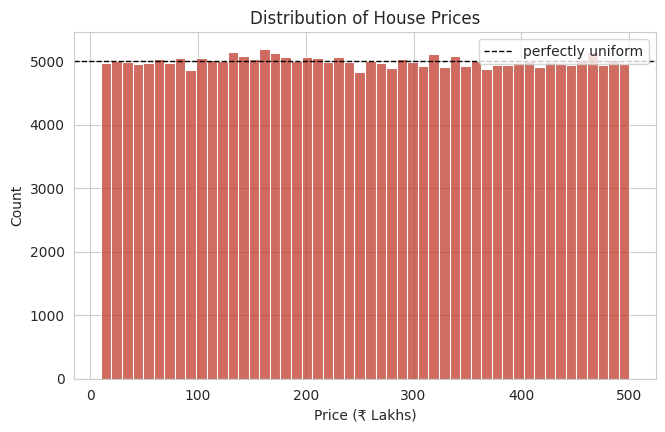

In [15]:
plot_price_distribution(df_clean)

**Price distribution:** prices are spread almost perfectly *evenly* between ₹10 lakh and ₹500 lakh (the dashed line is what a perfectly uniform distribution would look like). Real housing markets are right-skewed with a long expensive tail, so this is the first hint that this dataset is not a normal real-estate sample.

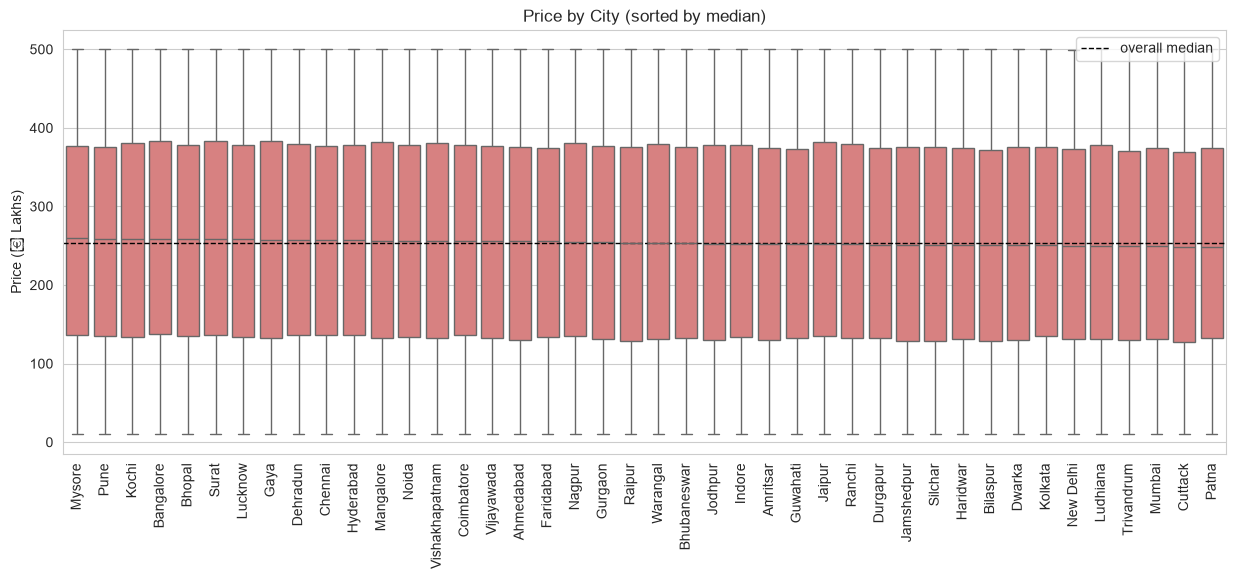

In [13]:
plot_price_by_city(df_clean)

In [14]:
loc_effects = categorical_effects(df_clean, ["City", "State", "Locality"])
print("Location effects - how much of the price variance do the location columns explain?")
loc_effects

Location effects - how much of the price variance do the location columns explain?


,n_groups,eta²,eta² expected by chance,F,p-value
feature,,,,,
State,20,9.66e-05,7.60e-05,1.27,0.19
City,42,1.90e-04,1.64e-04,1.16,0.22
Locality,500,2.04e-03,2.00e-03,1.02,0.35


**Location effect:** in a real market Mumbai/Delhi would sit far above Tier-2 cities. Here all 42 cities have practically the same median (₹248–260 lakh). Compare `eta²` (variance explained) with `eta² expected by chance`: they are essentially equal, i.e. location explains nothing beyond random noise.

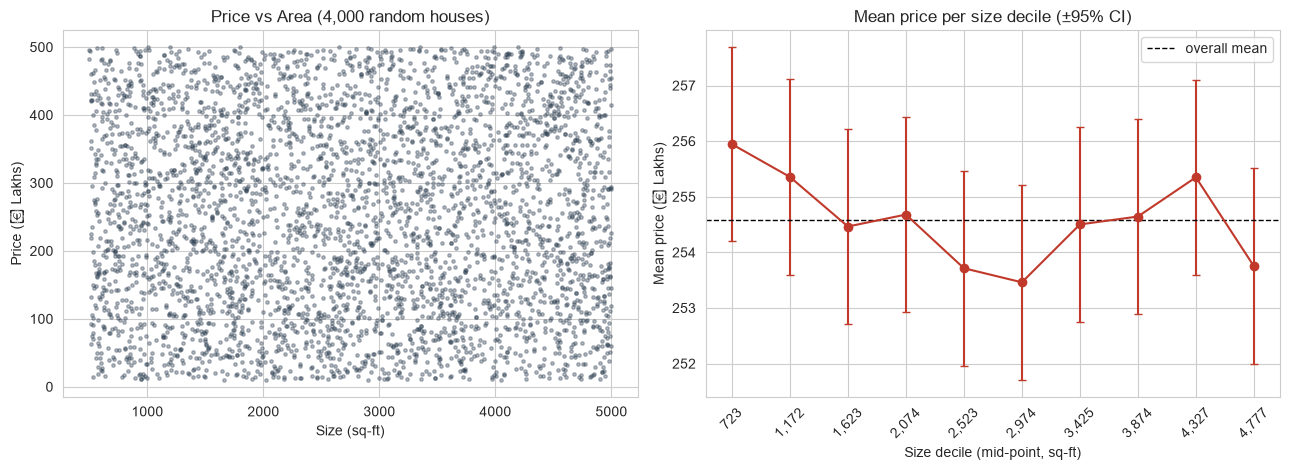

In [15]:
plot_price_vs_area(df_clean)

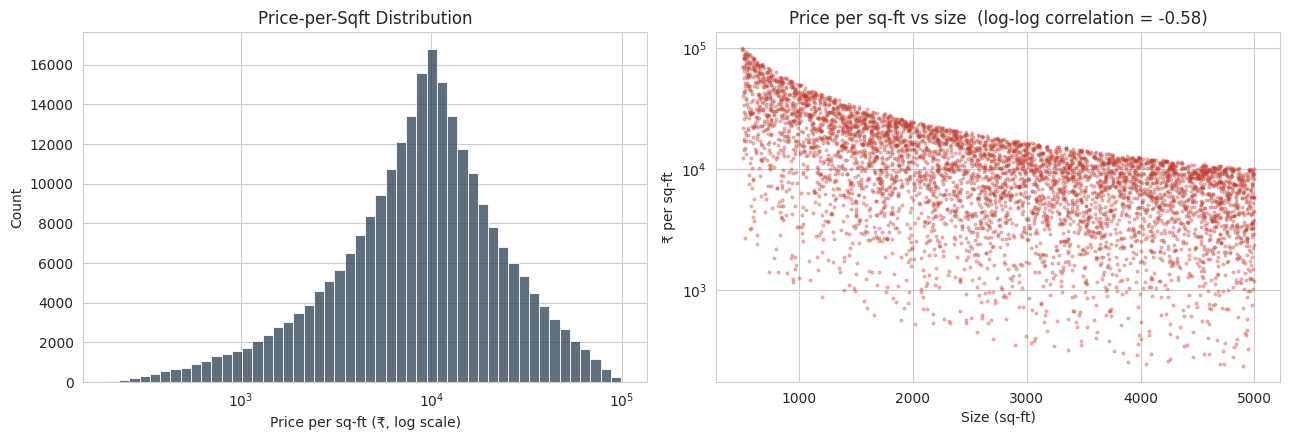

In [21]:
plot_price_per_sqft(df_clean)

**Area:** the mean price of each of the 10 size deciles is flat (right panel of the area plot) — a 5,000 sq-ft house is not priced higher than a 500 sq-ft one.
**Price per sq-ft:** because price is independent of size, `price ÷ size` simply falls as size grows (log-log correlation −0.58). The sharp upper edge of the scatter is just ₹500 lakh ÷ size: bigger houses look "cheaper per sq-ft" purely as an arithmetic artefact. That is also why `Price_per_SqFt` must never be used as a feature.

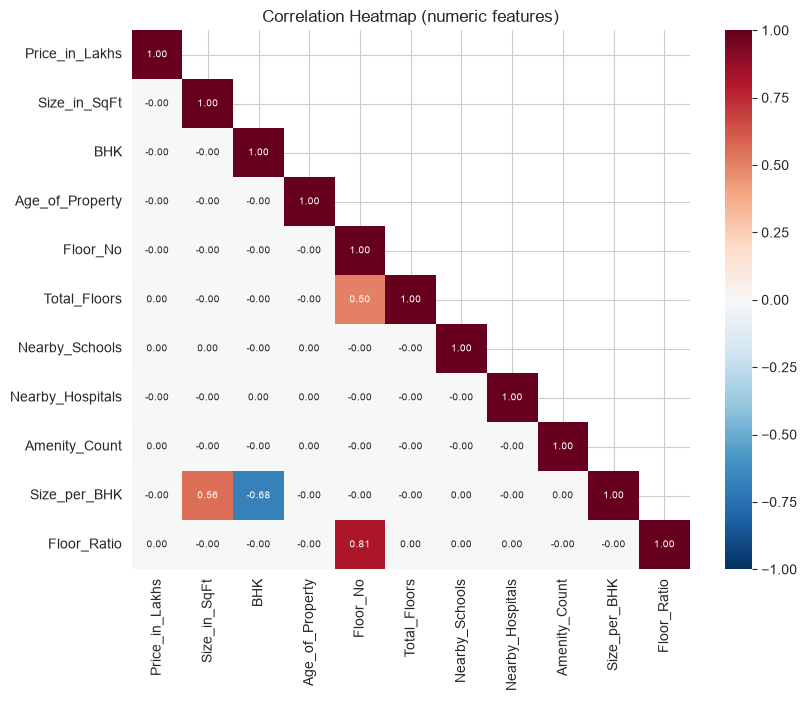

In [16]:
NUMERIC_EDA = ["Price_in_Lakhs", "Size_in_SqFt", "BHK", "Age_of_Property", "Floor_No", "Total_Floors",
               "Nearby_Schools", "Nearby_Hospitals", "Amenity_Count", "Size_per_BHK", "Floor_Ratio"]
plot_correlation_heatmap(df_clean, NUMERIC_EDA)

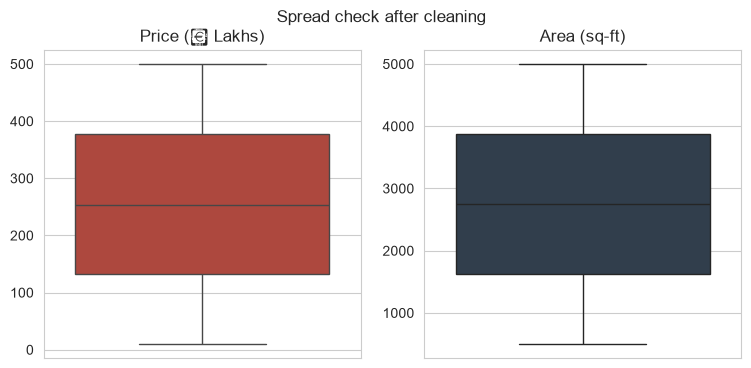

In [17]:
plot_outlier_boxplots(df_clean)

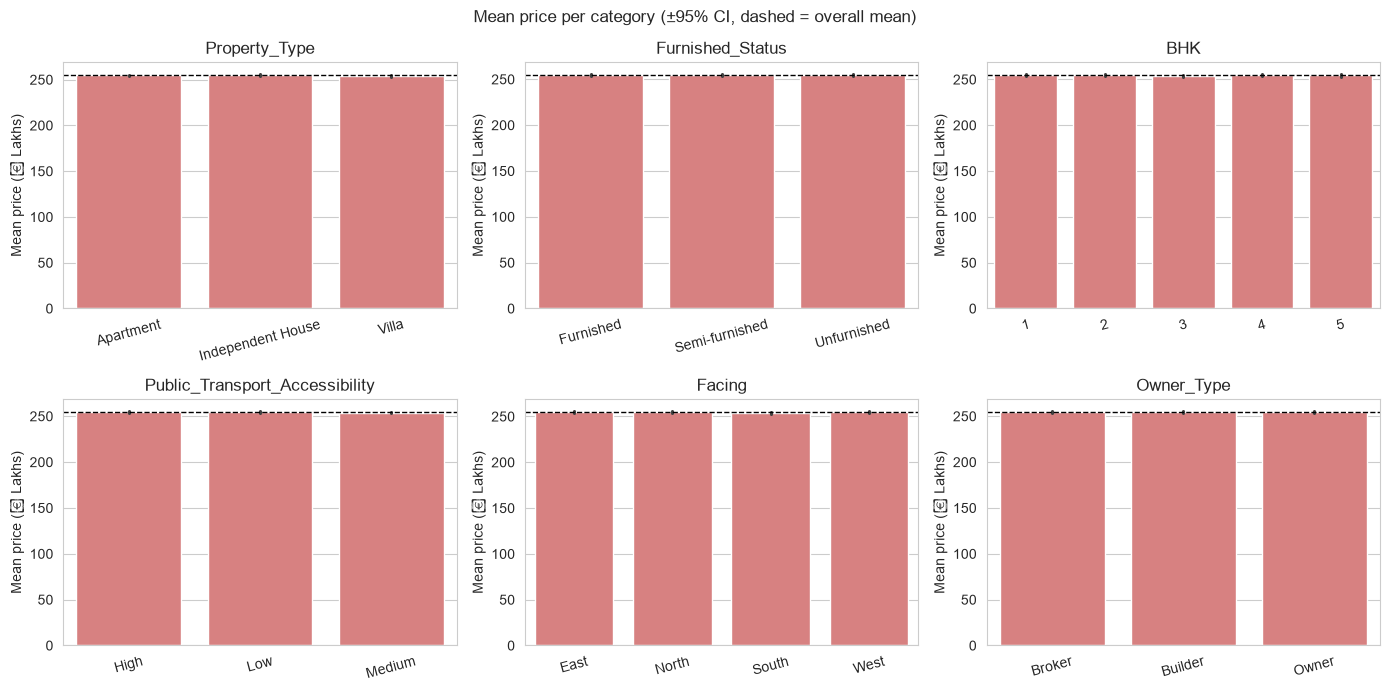

In [18]:
CAT_EDA = ["Property_Type", "Furnished_Status", "BHK", "Public_Transport_Accessibility", "Facing", "Owner_Type"]
plot_categorical_effects(df_clean, CAT_EDA)

**EDA takeaways**
* The target is uniformly distributed between ₹10 and ₹500 lakh; no outliers remain/need capping.
* Neither location, area, BHK, furnishing, amenities nor any other column shows a visible relationship with price (all group means sit on the dashed overall mean, all numeric correlations with price ≈ 0).
* `Size_in_SqFt` and `BHK` are uncorrelated (r ≈ 0) — unlike real houses where more bedrooms mean more area.
* This matters for modelling: **if the features carry no information, no model can reach a high R²**. §4–§5 test this rigorously rather than assume it.

## 4. Feature understanding and reduction
First we decide which columns may be used at all (leakage / redundancy), then we test which of the remaining features have any statistically detectable relationship with price.

In [19]:
NUM_FEATURES = ["BHK", "Size_in_SqFt", "Age_of_Property", "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals",
                "Parking_Space", "Security", "Amenity_Count"] + [f"Has_{a}" for a in AMENITY_LIST] + ["Size_per_BHK", "Floor_Ratio"]
CAT_FEATURES = ["City", "Property_Type", "Furnished_Status", "Public_Transport_Accessibility", "Facing", "Owner_Type", "Availability_Status"]
FEATURES_FULL = NUM_FEATURES + CAT_FEATURES

# --- redundancy checks done with code, not by eye ---
num_check = ["BHK", "Size_in_SqFt", "Year_Built", "Age_of_Property", "Floor_No", "Total_Floors", "Nearby_Schools",
             "Nearby_Hospitals", "Amenity_Count", "Size_per_BHK", "Floor_Ratio"]
c = df_clean[num_check].corr().abs()
pairs = [(a, b, round(c.loc[a, b], 3)) for i, a in enumerate(num_check) for b in num_check[i + 1:] if c.loc[a, b] > 0.9]
print("Feature pairs with |correlation| > 0.9:", pairs)
print("Max number of states per city:", int(df_clean.groupby("City")["State"].nunique().max()), "-> State adds nothing beyond City")
print("Distinct Locality values:", df_clean["Locality"].nunique(), "(anonymous labels, 500 levels)")

decision = pd.DataFrame([
    ("ID",                    "identifier",                         "dropped",  "no meaning"),
    ("Price_per_SqFt(_INR)",  "derived from the target",            "dropped",  "target leakage"),
    ("Year_Built",            "numeric",                            "dropped",  "|corr| = 1 with Age_of_Property (redundant)"),
    ("State",                 "categorical",                        "dropped",  "fully determined by City (redundant)"),
    ("Locality",              "categorical, 500 levels",            "dropped",  "anonymous labels; 500 sparse levels would add noise (tested in §3: no effect)"),
    ("Amenities (text)",      "text",                               "encoded",  "-> Has_<amenity> flags + Amenity_Count"),
    ("Parking_Space, Security","Yes/No",                            "encoded",  "-> 1/0"),
    ("Size_in_SqFt, BHK, ...", "numeric",                           "kept",     "tested below"),
    ("City, Property_Type, ...", "categorical",                     "kept",     "one-hot encoded; tested below"),
], columns=["column", "kind", "decision", "reason"])
print(f"\nCandidate features after removing leakage/redundancy: {len(FEATURES_FULL)} ({len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical)")
decision

Feature pairs with |correlation| > 0.9: [('Year_Built', 'Age_of_Property', np.float64(1.0))]
Max number of states per city: 1 -> State adds nothing beyond City
Distinct Locality values: 500 (anonymous labels, 500 levels)

Candidate features after removing leakage/redundancy: 24 (17 numeric + 7 categorical)


,column,kind,decision,reason
0,ID,identifier,dropped,no meaning
1,Price_per_SqFt(_INR),derived from the target,dropped,target leakage
2,Year_Built,numeric,dropped,|corr| = 1 with Age_of_Property (redundant)
3,State,categorical,dropped,fully determined by City (redundant)
4,Locality,"categorical, 500 levels",dropped,anonymous labels; 500 sparse levels would add ...
5,Amenities (text),text,encoded,-> Has_<amenity> flags + Amenity_Count
6,"Parking_Space, Security",Yes/No,encoded,-> 1/0
7,"Size_in_SqFt, BHK, ...",numeric,kept,tested below
8,"City, Property_Type, ...",categorical,kept,one-hot encoded; tested below


In [20]:
# --- which features carry ANY detectable signal about price? (Bonferroni-corrected, all 250k rows) ---
y_all = df_clean["Price_in_Lakhs"]
rows = []
for f in NUM_FEATURES:
    r, p = stats.pearsonr(df_clean[f], y_all)
    rows.append({"feature": f, "test": "Pearson", "effect size": abs(r), "p-value": p})
cat_tab = categorical_effects(df_clean, CAT_FEATURES)
for f, r in cat_tab.iterrows():
    rows.append({"feature": f, "test": "ANOVA (eta²)", "effect size": r["eta²"], "p-value": r["p-value"]})

sig = pd.DataFrame(rows).set_index("feature").sort_values("p-value")
alpha = 0.05 / len(sig)                                           # Bonferroni: 0.05 / number of tests
sig["significant"] = sig["p-value"] < alpha
print(f"Bonferroni threshold: p < {alpha:.4f}  ({len(sig)} tests)  ->  {int(sig['significant'].sum())} feature(s) significant")

n_keep = max(5, int(sig["significant"].sum()))                    # keep every significant feature, never fewer than the 5 best
FEATURES_REDUCED = sig.index[:n_keep].tolist()
print("Reduced feature set (5 smallest p-values):", FEATURES_REDUCED)
sig

Bonferroni threshold: p < 0.0021  (24 tests)  ->  0 feature(s) significant
Reduced feature set (5 smallest p-values): ['Security', 'Property_Type', 'Availability_Status', 'Nearby_Hospitals', 'Age_of_Property']


,test,effect size,p-value,significant
feature,,,,
Security,Pearson,3.81e-03,0.06,False
Property_Type,ANOVA (eta²),2.16e-05,0.07,False
Availability_Status,ANOVA (eta²),7.88e-06,0.16,False
Nearby_Hospitals,Pearson,2.77e-03,0.17,False
Age_of_Property,Pearson,2.71e-03,0.17,False
Size_in_SqFt,Pearson,2.53e-03,0.21,False
City,ANOVA (eta²),1.90e-04,0.22,False
Public_Transport_Accessibility,ANOVA (eta²),9.39e-06,0.31,False
Has_Gym,Pearson,1.94e-03,0.33,False


**Feature reduction result:** after removing leakage/redundancy (ID, price-per-sqft, Year_Built, State, Locality) the test above finds **no feature that is statistically related to price** once we correct for running 24 tests. So there is no principled way to "keep only the useful features" — none are useful. We still build a 5-feature reduced set (the 5 lowest p-values) and compare it with the full set in §5c, which confirms the metrics do not change.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preview_prep = ColumnTransformer([("num", "passthrough", NUM_FEATURES),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)]).fit(df_clean[FEATURES_FULL])
X_preview = pd.DataFrame(preview_prep.transform(df_clean[FEATURES_FULL].head(5)), columns=preview_prep.get_feature_names_out())
print(f"One-hot feature matrix: {len(preview_prep.get_feature_names_out())} columns "
      f"({len(NUM_FEATURES)} numeric + {len(preview_prep.get_feature_names_out()) - len(NUM_FEATURES)} one-hot columns)")
X_preview.iloc[:, :12]

One-hot feature matrix: 77 columns (17 numeric + 60 one-hot columns)


,num__BHK,num__Size_in_SqFt,num__Age_of_Property,num__Floor_No,num__Total_Floors,num__Nearby_Schools,num__Nearby_Hospitals,num__Parking_Space,num__Security,num__Amenity_Count,num__Has_Clubhouse,num__Has_Garden
0,4.00,692.00,3.00,15.00,24.00,6.00,6.00,1.00,0.00,2.00,0.00,0.00
1,2.00,"3,094.00",10.00,3.00,18.00,3.00,8.00,0.00,0.00,4.00,1.00,1.00
2,3.00,"4,993.00",30.00,19.00,27.00,10.00,1.00,0.00,0.00,5.00,1.00,1.00
3,1.00,"2,461.00",7.00,14.00,20.00,10.00,5.00,1.00,0.00,2.00,0.00,0.00
4,2.00,"4,535.00",34.00,5.00,25.00,5.00,9.00,0.00,1.00,1.00,0.00,0.00


## 5. Modeling
Baseline (mean / median) + Linear, Ridge, Lasso, Decision Tree, Random Forest and Gradient Boosting.

How we get the best result honestly:
* **Randomised** 80/20 split (`shuffle=True`) and shuffled 3-fold cross-validation.
* **Hyper-parameter tuning** with `RandomizedSearchCV` (scored on MAE) on a random 40k-row subset of the *training* data, then the best setting is refit on the full training set.
* Models are ranked on **cross-validation MAE** — the test set is only used for the final report, never for choosing.
* One-hot encoding lives *inside* a scikit-learn `Pipeline`, so training and prediction always use the identical encoding.

In [23]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import time


def evaluate(y_true_lakh, y_pred_lakh) -> dict:
    """Metrics in rupees (and %) - inputs are in lakhs."""
    yt = np.asarray(y_true_lakh, float) * LAKH
    yp = np.asarray(y_pred_lakh, float) * LAKH
    return {"MAE (₹)": mean_absolute_error(yt, yp),
            "RMSE (₹)": float(np.sqrt(mean_squared_error(yt, yp))),
            "R²": r2_score(yt, yp),
            "MAPE (%)": float(np.mean(np.abs((yt - yp) / yt)) * 100)}


MODEL_SPECS = {   # name: (estimator factory, needs feature scaling?)
    "Linear Regression": (lambda: LinearRegression(), True),
    "Ridge Regression":  (lambda: Ridge(), True),
    "Lasso Regression":  (lambda: Lasso(max_iter=20000), True),
    "Decision Tree":     (lambda: DecisionTreeRegressor(random_state=SEED), False),
    "Random Forest":     (lambda: RandomForestRegressor(n_estimators=100, max_samples=0.25, n_jobs=-1, random_state=SEED), False),
    "Gradient Boosting": (lambda: HistGradientBoostingRegressor(early_stopping=False, random_state=SEED), False),
}


def build_model(name, feats, params=None):
    """Pipeline = one-hot encoding (+ scaling for linear models) + estimator."""
    est_fn, scale = MODEL_SPECS[name]
    num = [f for f in feats if f in NUM_FEATURES]
    cat = [f for f in feats if f in CAT_FEATURES]
    pre = ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    pipe = Pipeline([("prep", pre), ("model", est_fn())])
    return pipe.set_params(**params) if params else pipe

In [25]:
y = df_clean["Price_in_Lakhs"]
X = df_clean[FEATURES_FULL]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=SEED)
print(f"Train: {len(X_train):,} rows   Test: {len(X_test):,} rows   (randomised split)")

results = {}
results["Baseline (mean)"]   = evaluate(y_test, DummyRegressor(strategy="mean").fit(X_train, y_train).predict(X_test))
results["Baseline (median)"] = evaluate(y_test, DummyRegressor(strategy="median").fit(X_train, y_train).predict(X_test))
pd.DataFrame(results).T

Train: 200,000 rows   Test: 50,000 rows   (randomised split)


,MAE (₹),RMSE (₹),R²,MAPE (%)
Baseline (mean),"12,246,271.25","14,135,308.27",-9.54e-07,134.28
Baseline (median),"12,245,990.50","14,135,333.67",-4.55e-06,134.05


In [26]:
SEARCH_GRIDS = {
    "Linear Regression": {},
    "Ridge Regression":  {"model__alpha": [0.1, 1, 10, 100, 1000, 10000]},
    "Lasso Regression":  {"model__alpha": [0.01, 0.1, 1, 10]},
    "Decision Tree":     {"model__max_depth": [2, 3, 4, 6, 8], "model__min_samples_leaf": [50, 200, 500, 1000]},
    "Random Forest":     {"model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [20, 50, 100, 300],
                          "model__max_features": [0.3, 0.5, "sqrt"]},
    "Gradient Boosting": {"model__learning_rate": [0.02, 0.05, 0.1], "model__max_depth": [2, 3, 4, 6],
                          "model__max_iter": [100, 200, 400], "model__min_samples_leaf": [50, 200, 500],
                          "model__l2_regularization": [0, 1, 10]},
}
N_ITER = 10
cv = KFold(n_splits=3, shuffle=True, random_state=SEED)                      # shuffled folds
tune_idx = X_train.sample(40000, random_state=SEED).index                    # random tuning subset of the TRAIN data
X_tune, y_tune = X_train.loc[tune_idx], y_train.loc[tune_idx]

fitted, best_params, cv_mae = {}, {}, {}
for name, grid in SEARCH_GRIDS.items():
    t0 = time.time()
    base = build_model(name, FEATURES_FULL)
    if grid:
        n_combo = int(np.prod([len(v) for v in grid.values()]))
        rs = RandomizedSearchCV(base, grid, n_iter=min(N_ITER, n_combo), cv=cv, scoring="neg_mean_absolute_error",
                                random_state=SEED, n_jobs=1, refit=False).fit(X_tune, y_tune)
        best_params[name], cv_mae[name] = rs.best_params_, -rs.best_score_
    else:
        from sklearn.model_selection import cross_val_score
        best_params[name] = {}
        cv_mae[name] = -cross_val_score(base, X_tune, y_tune, cv=cv, scoring="neg_mean_absolute_error").mean()
    fitted[name] = build_model(name, FEATURES_FULL, best_params[name]).fit(X_train, y_train)     # refit on the FULL training set
    results[name] = evaluate(y_test, fitted[name].predict(X_test))
    results[name]["CV MAE (₹ Lakh)"] = cv_mae[name]
    print(f"{name:<18} done in {time.time() - t0:5.0f}s   best params: {best_params[name]}")

Linear Regression  done in     1s   best params: {}
Ridge Regression   done in     2s   best params: {'model__alpha': 10000}
Lasso Regression   done in     2s   best params: {'model__alpha': 10}
Decision Tree      done in     5s   best params: {'model__min_samples_leaf': 1000, 'model__max_depth': 2}
Random Forest      done in    11s   best params: {'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': 6}
Gradient Boosting  done in    28s   best params: {'model__min_samples_leaf': 50, 'model__max_iter': 100, 'model__max_depth': 2, 'model__learning_rate': 0.02, 'model__l2_regularization': 1}


In [28]:
for name, mdl in fitted.items():
    results[name]["Prediction spread (₹ Lakh)"] = float(np.std(mdl.predict(X_test)))      # std of the predictions themselves
results_df = pd.DataFrame(results).T[["CV MAE (₹ Lakh)", "MAE (₹)", "RMSE (₹)", "R²", "MAPE (%)", "Prediction spread (₹ Lakh)"]]
ml_only = results_df.drop(index=[i for i in results_df.index if "Baseline" in i])

cv_winner = ml_only["CV MAE (₹ Lakh)"].astype(float).idxmin()                          # lowest cross-validated MAE (test set not used)
is_constant = ml_only["Prediction spread (₹ Lakh)"].astype(float) < 0.001 * y_train.std()   # < 0.1% of the price std = effectively constant
best_name = ml_only.loc[~is_constant, "CV MAE (₹ Lakh)"].astype(float).idxmin()          # best model whose predictions actually vary
best_model = fitted[best_name]
print(f"Lowest CV MAE overall : {cv_winner}  (prediction spread = {ml_only.loc[cv_winner, 'Prediction spread (₹ Lakh)']:.3f} lakh"
      + ("  -> it predicts the same price for every house, i.e. it IS the baseline)" if is_constant[cv_winner] else ")"))
print(f"Model used from here on: {best_name}  (best CV MAE among models that actually use the inputs)")
results_df.sort_values("MAE (₹)")

Lowest CV MAE overall : Lasso Regression  (prediction spread = 0.000 lakh  -> it predicts the same price for every house, i.e. it IS the baseline)
Model used from here on: Gradient Boosting  (best CV MAE among models that actually use the inputs)


,CV MAE (₹ Lakh),MAE (₹),RMSE (₹),R²,MAPE (%),Prediction spread (₹ Lakh)
Baseline (median),NaN,"12,245,990.50","14,135,333.67",-4.55e-06,134.05,NaN
Decision Tree,122.15,"12,246,003.53","14,135,412.03",-1.56e-05,134.29,1.44
Random Forest,122.14,"12,246,147.62","14,135,572.04",-3.83e-05,134.33,1.40
Baseline (mean),NaN,"12,246,271.25","14,135,308.27",-9.54e-07,134.28,NaN
Lasso Regression,122.10,"12,246,271.25","14,135,308.27",-9.54e-07,134.28,8.53e-14
Gradient Boosting,122.13,"12,246,299.93","14,135,392.02",-1.28e-05,134.28,0.84
Ridge Regression,122.14,"12,246,343.41","14,135,668.73",-5.20e-05,134.28,1.51
Linear Regression,122.22,"12,247,723.70","14,137,374.14",-2.93e-04,134.28,2.71


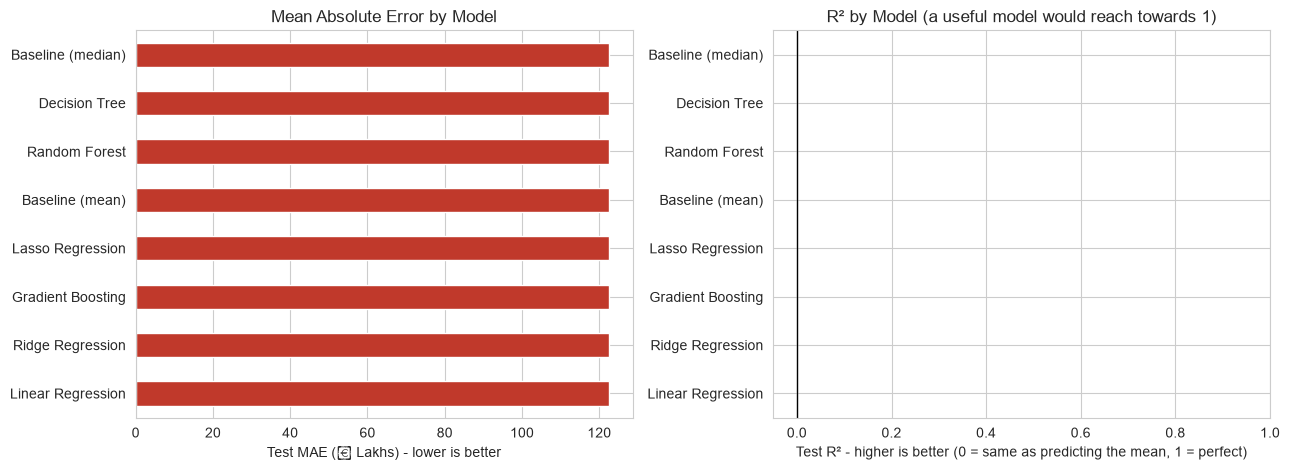

In [29]:
def plot_model_comparison(results_df, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    order = results_df["MAE (₹)"].astype(float).sort_values().index
    (results_df.loc[order, "MAE (₹)"] / LAKH).plot(kind="barh", ax=axes[0], color="#c0392b")
    axes[0].set_xlabel("Test MAE (₹ Lakhs) - lower is better"); axes[0].set_title("Mean Absolute Error by Model"); axes[0].invert_yaxis()
    results_df.loc[order, "R²"].astype(float).plot(kind="barh", ax=axes[1], color="#2c3e50")
    axes[1].axvline(0, color="black", lw=1); axes[1].set_xlim(-0.05, 1.0)          # full 0-1 scale, so noise is not magnified
    axes[1].set_xlabel("Test R² - higher is better (0 = same as predicting the mean, 1 = perfect)")
    axes[1].set_title("R² by Model (a useful model would reach towards 1)"); axes[1].invert_yaxis()
    fig.tight_layout(); _finish(fig, "model_comparison.png", **kw)

plot_model_comparison(results_df)
results_df.round(4).to_csv("outputs/model_comparison.csv")

**Reading the results:** every model, tuned or not, ends up with **R² ≈ 0** and an MAE equal to the baseline's — about ₹1.22 crore (~122 lakh) on a price range of ₹10–500 lakh, i.e. a MAPE of ~134%. The differences between models (a few hundred rupees out of ₹1.2 crore) are noise.

Note the **Lasso** row: cross-validation picked α = 10, which shrinks *every* coefficient to zero, so Lasso predicts the training mean for all houses (prediction spread = 0). That is the strongest possible hint that the best "model" for this data is the mean itself. Since a constant cannot be used for a prediction function, the rest of the notebook uses the best-CV model whose predictions actually depend on the inputs (marked in the output above). §5b tests whether any model could do better.

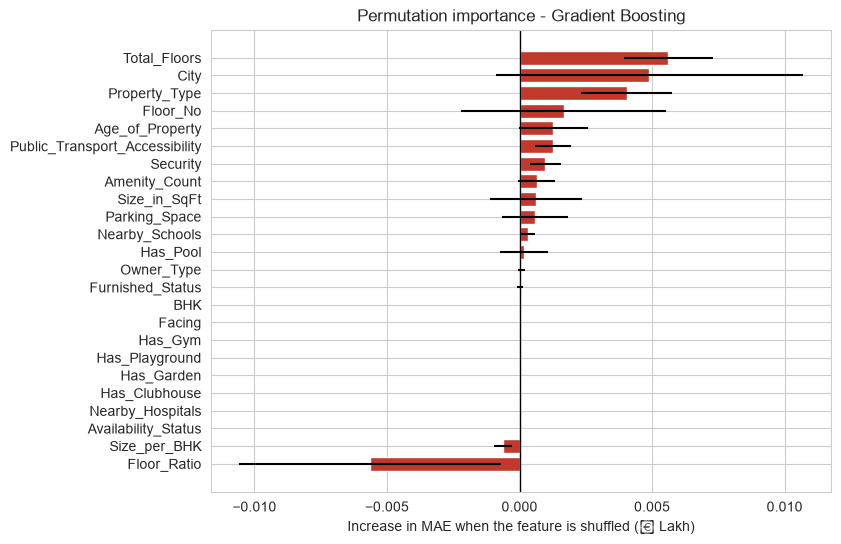

,MAE increase when shuffled (₹ Lakh),std
Total_Floors,5.62e-03,1.69e-03
City,4.90e-03,5.79e-03
Property_Type,4.05e-03,1.72e-03
Floor_No,1.66e-03,3.86e-03
Age_of_Property,1.27e-03,1.30e-03
Public_Transport_Accessibility,1.25e-03,6.81e-04
Security,9.75e-04,5.87e-04
Amenity_Count,6.51e-04,6.91e-04


In [30]:
# permutation importance on raw columns (one-hot columns of a feature are shuffled together)
samp = X_test.sample(10000, random_state=SEED).index
pi = permutation_importance(best_model, X_test.loc[samp], y_test.loc[samp], scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.DataFrame({"MAE increase when shuffled (₹ Lakh)": pi.importances_mean, "std": pi.importances_std},
                          index=FEATURES_FULL).sort_values("MAE increase when shuffled (₹ Lakh)", ascending=False)

def plot_feature_importance(imp, **kw):
    fig, ax = plt.subplots(figsize=(8, 6))
    d = imp.iloc[::-1]
    ax.barh(d.index, d.iloc[:, 0], xerr=d["std"], color="#c0392b", ecolor="black")
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"Permutation importance - {best_name}"); ax.set_xlabel("Increase in MAE when the feature is shuffled (₹ Lakh)")
    _finish(fig, "feature_importance.png", **kw)

plot_feature_importance(importance)
importance.head(8)

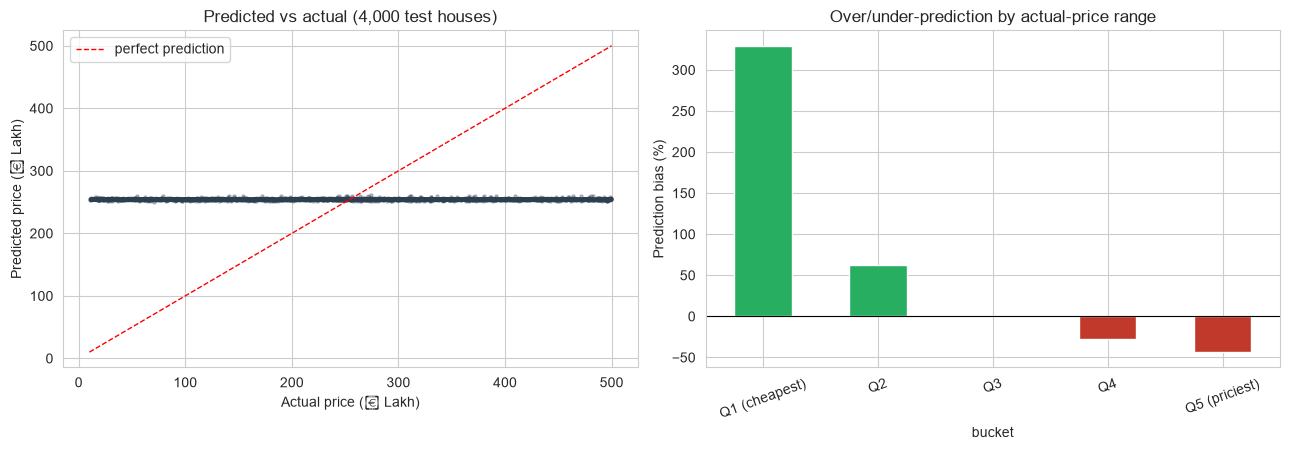

,n,mean actual (₹ Lakh),mean predicted (₹ Lakh),bias (%)
bucket,,,,
Q1 (cheapest),10002,59.30,254.62,329.40
Q2,9998,156.66,254.62,62.54
Q3,10001,253.10,254.62,0.60
Q4,10000,352.28,254.62,-27.72
Q5 (priciest),9999,451.09,254.62,-43.55


In [31]:
def price_bucket_bias(y_test, y_pred, n_bins=5) -> pd.DataFrame:
    res = pd.DataFrame({"actual": np.asarray(y_test, float), "pred": np.asarray(y_pred, float)})
    labels = [f"Q{i+1}" for i in range(n_bins)]; labels[0] += " (cheapest)"; labels[-1] += " (priciest)"
    res["bucket"] = pd.qcut(res["actual"], n_bins, labels=labels)
    g = res.groupby("bucket", observed=True)
    out = pd.DataFrame({"n": g.size(), "mean actual (₹ Lakh)": g["actual"].mean(), "mean predicted (₹ Lakh)": g["pred"].mean()})
    out["bias (%)"] = (out["mean predicted (₹ Lakh)"] - out["mean actual (₹ Lakh)"]) / out["mean actual (₹ Lakh)"] * 100
    return out

def plot_residual_check(y_test, y_pred, bias_df, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    idx = np.random.default_rng(SEED).choice(len(y_test), 4000, replace=False)
    axes[0].scatter(np.asarray(y_test)[idx], np.asarray(y_pred)[idx], s=5, alpha=0.3, color="#2c3e50")
    axes[0].plot([10, 500], [10, 500], "r--", lw=1, label="perfect prediction")
    axes[0].set_xlabel("Actual price (₹ Lakh)"); axes[0].set_ylabel("Predicted price (₹ Lakh)")
    axes[0].set_title("Predicted vs actual (4,000 test houses)"); axes[0].legend()
    cols = ["#c0392b" if v < 0 else "#27ae60" for v in bias_df["bias (%)"]]
    bias_df["bias (%)"].plot(kind="bar", ax=axes[1], color=cols); axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set_ylabel("Prediction bias (%)"); axes[1].set_title("Over/under-prediction by actual-price range"); axes[1].tick_params(axis="x", rotation=20)
    fig.tight_layout(); _finish(fig, "residual_check.png", **kw)

y_pred_test = best_model.predict(X_test)
bias_df = price_bucket_bias(y_test, y_pred_test)
plot_residual_check(y_test, y_pred_test, bias_df)
bias_df

**Residual check:** the predictions form a nearly horizontal band — the model outputs roughly the average price (~₹255 lakh) for every house. A model that has learned nothing over-predicts cheap houses and under-predicts expensive ones by construction (regression to the mean), which is exactly what the bias chart shows. A model with real signal would hug the red diagonal.

(The permutation-importance table above agrees: shuffling any feature changes the MAE by only ~0.005 lakh = ₹500 on an error of ₹1.2 crore, and the spread across repeats is as large as the effect — no feature is important.)

### 5b. Sanity checks — is there any signal at all?
Four checks:
1. **Shuffled-target control** — train the same model on *randomly shuffled prices*. If the real model scores the same as this control, it has learned nothing.
2. **Leakage demo** — add `Price_per_SqFt` (= price ÷ size) as a feature. The score jumps, but only because the answer is hidden in the input — which is why it is excluded.
3. **Paired bootstrap** — does the model beat simply predicting the mean? (95% confidence interval)
4. **Kitchen sink** — give a model *every* raw column (even `ID`, `Locality`, `State`) to look for hidden structure.

In [32]:
# 1. shuffled-target control
y_perm = np.random.default_rng(SEED).permutation(y_train.to_numpy())
control = clone(best_model).fit(X_train, y_perm)
ctrl = evaluate(y_test, control.predict(X_test))

# 2. leakage demo (NOT a valid model)
leak_feat = ["Price_per_SqFt_INR"]
leak_pipe = Pipeline([("prep", ColumnTransformer([("num", "passthrough", NUM_FEATURES + leak_feat),
                                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)])),
                      ("model", HistGradientBoostingRegressor(max_iter=200, random_state=SEED))])
Xl = df_clean[FEATURES_FULL + leak_feat]
Xl_tr, Xl_te = Xl.loc[X_train.index], Xl.loc[X_test.index]
leak = evaluate(y_test, leak_pipe.fit(Xl_tr, y_train).predict(Xl_te))

# 3. paired bootstrap: is the model better than just predicting the mean?  (positive = model better)
base_pred = np.full(len(y_test), y_train.mean())
gain = np.abs(y_test.to_numpy() - base_pred) - np.abs(y_test.to_numpy() - y_pred_test)       # lakh saved per house
rng = np.random.default_rng(SEED)
boot = np.array([gain[rng.integers(0, len(gain), len(gain))].mean() for _ in range(1000)])
ci = np.percentile(boot, [2.5, 97.5])

# 4. kitchen-sink: EVERY raw column incl. ID (original row order), Locality and State, as plain codes
ks = df_clean.drop(columns=["Price_in_Lakhs", "Price_INR", "Price_per_SqFt_INR", "Amenities"]).copy()
for col in ks.select_dtypes(exclude="number").columns:
    ks[col] = ks[col].astype("category").cat.codes
ks_model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)
kitchen = evaluate(y_test, ks_model.fit(ks.loc[X_train.index], y_train).predict(ks.loc[X_test.index]))

control_df = pd.DataFrame({
    f"Real model ({best_name})": results[best_name],
    "Same model, SHUFFLED prices": ctrl,
    "Kitchen sink: ALL raw columns (ID, Locality, State...)": kitchen,
    "LEAKAGE: + Price_per_SqFt feature": leak,
}).T[["MAE (₹)", "RMSE (₹)", "R²", "MAPE (%)"]]
verdict = ("the model is NOT better than predicting the mean (CI entirely <= 0)" if ci[1] <= 0 else
           "the model beats the mean" if ci[0] > 0 else "no detectable difference from predicting the mean (CI contains 0)")
print(f"Paired bootstrap, MAE saved per house vs the mean baseline: {np.mean(gain):+.3f} lakh, 95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]  ->  {verdict}")
control_df

Paired bootstrap, MAE saved per house vs the mean baseline: -0.000 lakh, 95% CI [-0.008, +0.007]  ->  no detectable difference from predicting the mean (CI contains 0)


,MAE (₹),RMSE (₹),R²,MAPE (%)
Real model (Gradient Boosting),"12,246,299.93","14,135,392.02",-1.28e-05,134.28
"Same model, SHUFFLED prices","12,246,717.04","14,135,808.07",-7.17e-05,134.29
"Kitchen sink: ALL raw columns (ID, Locality, State...)","12,246,987.48","14,136,213.48",-1.29e-04,134.30
LEAKAGE: + Price_per_SqFt feature,"248,455.39","366,855.20",1.00,1.40


**What this proves**
* The real model and the same model trained on *randomly shuffled prices* are indistinguishable (both R² ≈ 0, MAEs within ~₹500 of each other on an error of ₹1.2 crore).
* The paired bootstrap shows the model saves ≈ 0 lakh per house compared with simply predicting the mean, with a 95% interval that contains 0.
* A "kitchen-sink" gradient-boosting model that is given **every** column — including the original row order (`ID`), the 500 `Locality` labels and `State` — also gets R² ≈ 0, so there is no hidden structure to exploit.
* The only way to get a high score is the leaked `Price_per_SqFt` column (R² ≈ 1.00, MAPE ≈ 1.4%), which is cheating because it contains the price itself.

So R² ≈ 0 is the **true ceiling for this file**, not a modelling failure.

### 5c. Feature reduction check — full vs reduced feature set
Does the model get worse if we keep only the 5 "best" features from §4?

In [33]:
rows = {}
for label, feats in [(f"All features ({len(FEATURES_FULL)})", FEATURES_FULL), (f"Reduced ({len(FEATURES_REDUCED)})", FEATURES_REDUCED)]:
    m = build_model(best_name, feats, best_params[best_name]).fit(X_train[feats], y_train)
    rows[label] = evaluate(y_test, m.predict(X_test[feats]))
pd.DataFrame(rows).T

,MAE (₹),RMSE (₹),R²,MAPE (%)
All features (24),"12,246,299.93","14,135,392.02",-1.28e-05,134.28
Reduced (5),"12,246,282.09","14,135,317.00",-2.19e-06,134.28


The reduced set (5 inputs instead of 24) gives exactly the same error, so it is the simpler choice — but since neither set can predict price, this mainly demonstrates the reduction workflow.

## 6. Extensions
**(a)** Price-category classification (Low / Medium / High). **(b)** City-wise models vs. one global model.

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

price_cat = pd.qcut(df_clean["Price_in_Lakhs"], q=3, labels=["Low", "Medium", "High"])
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, price_cat, test_size=0.2, shuffle=True, random_state=SEED, stratify=price_cat)

def build_classifier():
    pre = ColumnTransformer([("num", "passthrough", NUM_FEATURES),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)])
    return Pipeline([("prep", pre), ("model", RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=50,
                                                                     max_samples=0.25, n_jobs=-1, random_state=SEED))])

clf = build_classifier().fit(Xc_train, yc_train)
pred_c = clf.predict(Xc_test)
dummy = DummyClassifier(strategy="most_frequent").fit(Xc_train, yc_train).predict(Xc_test)
pd.DataFrame({
    "Random Forest classifier": {"accuracy": accuracy_score(yc_test, pred_c), "F1 (weighted)": f1_score(yc_test, pred_c, average="weighted")},
    "Always predict one class":  {"accuracy": accuracy_score(yc_test, dummy),  "F1 (weighted)": f1_score(yc_test, dummy,  average="weighted")},
    "Pure chance (3 classes)":   {"accuracy": 1 / 3, "F1 (weighted)": np.nan},
}).T

,accuracy,F1 (weighted)
Random Forest classifier,0.33,0.33
Always predict one class,0.33,0.17
Pure chance (3 classes),0.33,NaN


In [35]:
# city-wise models: one Random Forest per city, trained and tested on the SAME split as the global model
city_feats = [f for f in FEATURES_FULL if f != "City"]
city_params = {"model__max_depth": 6, "model__min_samples_leaf": 30, "model__n_estimators": 80, "model__max_samples": None}
rows, city_pred = [], pd.Series(index=X_test.index, dtype=float)
for city in sorted(df_clean["City"].unique()):
    tr, te = X_train["City"] == city, X_test["City"] == city
    m = build_model("Random Forest", city_feats, city_params).fit(X_train.loc[tr, city_feats], y_train[tr])
    city_pred[te] = m.predict(X_test.loc[te, city_feats])
    rows.append({"city": city, "n_train": int(tr.sum()), "n_test": int(te.sum()),
                 "city-model MAE (₹ Lakh)": mean_absolute_error(y_test[te], city_pred[te]),
                 "global-model MAE (₹ Lakh)": mean_absolute_error(y_test[te], best_model.predict(X_test.loc[te]))})
city_results = pd.DataFrame(rows).set_index("city")

g_mae = mean_absolute_error(y_test, best_model.predict(X_test)) * LAKH
c_mae = mean_absolute_error(y_test, city_pred) * LAKH
print(f"Global {best_name} MAE:      ₹{g_mae:,.0f}")
print(f"City-wise Random Forests MAE: ₹{c_mae:,.0f}")
print(f"Cities where the city-specific model beat the global one: "
      f"{int((city_results['city-model MAE (₹ Lakh)'] < city_results['global-model MAE (₹ Lakh)']).sum())} of {len(city_results)}")
city_results.head(10)

Global Gradient Boosting MAE:      ₹12,246,300
City-wise Random Forests MAE: ₹12,268,379
Cities where the city-specific model beat the global one: 11 of 42


,n_train,n_test,city-model MAE (₹ Lakh),global-model MAE (₹ Lakh)
city,,,,
Ahmedabad,5180,1231,122.01,122.33
Amritsar,4961,1260,124.06,123.30
Bangalore,3315,829,122.83,122.27
Bhopal,5032,1252,122.22,122.09
Bhubaneswar,5068,1255,122.87,123.34
Bilaspur,4982,1281,123.89,123.98
Chennai,4948,1220,121.25,120.49
Coimbatore,5227,1234,118.77,118.96
Cuttack,5113,1245,123.81,123.63


**Extensions result:** the classifier scores about 1/3 accuracy — exactly chance for three equal-sized classes — and the city-wise models are no better than the global one (they are slightly *worse*, because each city model has only ~5,000 noisy training rows). Both agree with §5b: the features do not determine the price in this dataset.

## 7. Prediction Function
Takes a new house's attributes, applies the same cleaning/encoding used in training (the encoder is part of the saved pipeline) and returns a price **plus a realistic 90% range** taken from held-out residuals, so the user can see how (un)certain the estimate is.

In [37]:
def save_best_model(model, name, feats, residuals, path="outputs/best_model.joblib"):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    lo, hi = np.percentile(residuals, [5, 95])
    joblib.dump({"model": model, "model_name": name, "features": feats,
                 "known_cities": sorted(df_clean["City"].unique()),
                 "resid_q05_lakh": float(lo), "resid_q95_lakh": float(hi)}, path)
    return path

residuals = np.asarray(y_test, float) - y_pred_test
save_best_model(best_model, best_name, FEATURES_FULL, residuals)


def load_model_bundle(path="outputs/best_model.joblib") -> dict:
    return joblib.load(path)



def predict_price(
    bundle: dict,
    *,
    city,
    property_type,
    bhk,
    size_sqft,
    year_built,
    furnished_status="Unfurnished",
    floor_no=1,
    total_floors=5,
    nearby_schools=5,
    nearby_hospitals=5,
    public_transport="Medium",
    parking=False,
    security=False,
    amenities=(),
    facing="East",
    owner_type="Owner",
    availability="Ready_to_Move"
):
    """
    Predict the price of a house.

    Returns:
        Predicted price in lakhs and rupees,
        approximate 90% residual-based range,
        and a warning about model reliability.
    """

    # 1. Validate required inputs
    if not isinstance(city, str) or not city.strip():
        raise ValueError("City must be a non-empty string.")

    if city not in bundle["known_cities"]:
        raise ValueError(
            f"Unknown city: {city}. "
            f"Choose from: {bundle['known_cities']}"
        )

    if not isinstance(property_type, str) or not property_type.strip():
        raise ValueError("Enter a valid property type.")

    numeric_inputs = {
        "BHK": bhk,
        "Size in square feet": size_sqft,
        "Year built": year_built,
        "Floor number": floor_no,
        "Total floors": total_floors,
        "Nearby schools": nearby_schools,
        "Nearby hospitals": nearby_hospitals
    }

    for name, value in numeric_inputs.items():
        if not np.isscalar(value) or not np.isfinite(value):
            raise ValueError(f"{name} must be a finite number.")

    if bhk < 1 or size_sqft <= 0:
        raise ValueError("BHK must be at least 1 and area must be positive.")

    if year_built < 1800 or year_built > CURRENT_YEAR:
        raise ValueError(f"Year built must be between 1800 and {CURRENT_YEAR}.")

    if floor_no < 0 or total_floors < 1:
        raise ValueError("Floor number and total floors are invalid.")

    if floor_no > total_floors:
        raise ValueError("Floor number cannot exceed total floors.")

    if nearby_schools < 0 or nearby_hospitals < 0:
        raise ValueError("Nearby facility counts cannot be negative.")

    # 2. Prepare amenities
    if isinstance(amenities, str):
        amenities = [amenities] if amenities else []
    else:
        amenities = list(amenities)

    # 3. Build one row using the original training column names
    house = pd.DataFrame([{
        "City": city.strip(),
        "Property_Type": property_type.strip(),
        "BHK": bhk,
        "Size_in_SqFt": size_sqft,
        "Age_of_Property": CURRENT_YEAR - year_built,
        "Furnished_Status": furnished_status,
        "Floor_No": floor_no,
        "Total_Floors": total_floors,
        "Nearby_Schools": nearby_schools,
        "Nearby_Hospitals": nearby_hospitals,
        "Public_Transport_Accessibility": public_transport,
        "Parking_Space": int(bool(parking)),
        "Security": int(bool(security)),
        "Amenities": ", ".join(amenities),
        "Facing": facing,
        "Owner_Type": owner_type,
        "Availability_Status": availability
    }])

    # 4. Generate the same engineered features used in training
    house = add_engineered_features(house)

    # 5. Select features in exactly the training order
    features = bundle["features"]
    missing = set(features) - set(house.columns)

    if missing:
        raise ValueError(
            f"Missing model features: {sorted(missing)}"
        )

    X_new = house[features]

    # 6. Predict price in lakhs
    prediction = float(bundle["model"].predict(X_new)[0])
    prediction = max(prediction, 0.0)

    # 7. Estimate a residual-based prediction range
    low = max(
        0.0, prediction + bundle["resid_q05_lakh"]
    )
    high = max(
        low, prediction + bundle["resid_q95_lakh"]
    )

    # 8. Return structured results
    return {
        "city": city,
        "property_type": property_type,
        "bhk": int(bhk),
        "size_sqft": float(size_sqft),
        "price_lakh": round(prediction, 2),
        "price_inr": round(prediction * LAKH),
        "range_90pct_lakh": (round(low, 2), round(high, 2)),
        "reliability_warning": (
            "Predictions are unreliable because the current dataset "
            "shows almost no relationship between property features "
            "and prices."
        )
    }


In [38]:

bundle = load_model_bundle("outputs/best_model.joblib")

result = predict_price(
    bundle,
    city="Pune",
    property_type="Apartment",
    bhk=3,
    size_sqft=1400,
    year_built=2015,
    furnished_status="Semi-furnished",
    floor_no=4,
    total_floors=12,
    parking=True,
    security=True,
    amenities=["Gym", "Pool"]
)

print(f"City: {result['city']}")
print(f"Area: {result['size_sqft']:,.0f} sq. ft.")
print(f"Bedrooms: {result['bhk']}")
print(f"Estimated price: ₹{result['price_inr']:,}")
print(f"Price in lakhs: ₹{result['price_lakh']} lakh")
print(f"Approximate range: ₹{result['range_90pct_lakh']} lakh")
print(f"Reliability: {result['reliability_warning']}")


City: Pune
Area: 1,400 sq. ft.
Bedrooms: 3
Estimated price: ₹25,411,183
Price in lakhs: ₹254.11 lakh
Approximate range: ₹(33.55, 474.93) lakh
Reliability: Predictions are unreliable because the current dataset shows almost no relationship between property features and prices.


In [54]:
bundle = load_model_bundle("outputs/best_model.joblib")          # load the saved model, like a user of the project would
print("Loaded model:", bundle["model_name"], "\n")

new_houses = [
    dict(city="Pune", property_type="Apartment", bhk=3, size_sqft=1400, year_built=2015, furnished_status="Semi-furnished",
         floor_no=4, total_floors=12, parking=True, security=True, amenities=["Gym", "Pool"]),
    dict(city="Mumbai", property_type="Villa", bhk=5, size_sqft=3200, year_built=2020, furnished_status="Furnished",
         floor_no=1, total_floors=2, parking=True, security=True, amenities=["Gym", "Pool", "Clubhouse", "Garden"]),
    dict(city="Jaipur", property_type="Independent House", bhk=1, size_sqft=650, year_built=2005),
]
for h in new_houses:
    out = predict_price(bundle, **h)
    lo, hi = out["range_90pct_lakh"]
    print(f"{h['city']:<7} {h['property_type']:<18} {h['bhk']} BHK {h['size_sqft']:>5} sq-ft  ->  ₹{out['price_inr']:,}  "
          f"({out['price_lakh']} lakh),  90% range {lo}-{hi} lakh")

Loaded model: Gradient Boosting 

Pune    Apartment          3 BHK  1400 sq-ft  ->  ₹25,411,183  (254.1 lakh),  90% range 33.6-474.9 lakh
Mumbai  Villa              5 BHK  3200 sq-ft  ->  ₹25,478,907  (254.8 lakh),  90% range 34.2-475.6 lakh
Jaipur  Independent House  1 BHK   650 sq-ft  ->  ₹25,477,191  (254.8 lakh),  90% range 34.2-475.6 lakh


## Summary
- **Data**: real Kaggle file (250,000 listings, 42 cities), stored with numpy/pandas, **randomised** with a seeded shuffle, saved to CSV + **SQLite** (read / write / modify demonstrated) and loaded back from the database for modelling.
- **Cleaning**: no missing values or duplicates; 46.5% of rows had `Floor_No > Total_Floors` (fixed); no price/size outliers per the IQR rule; the leaking `Price_per_SqFt` column was removed.
- **EDA**: price is uniformly distributed (₹10–500 lakh) and shows **no** relation to city, area, BHK, furnishing or amenities (city medians ₹248–260 lakh; all |correlations| with price < 0.004).
- **Features**: 24 candidate features after removing leakage/redundancy; none significant after Bonferroni correction; a 5-feature reduced set performs identically to the full set.
- **Models** (baseline + Linear, Ridge, Lasso, Decision Tree, Random Forest, Gradient Boosting; tuned with randomised search + shuffled CV): all give **R² ≈ 0, MAE ≈ ₹1.22 crore, MAPE ≈ 134%** — identical to predicting the mean.
- **Why**: shuffled-target control, paired bootstrap and a kitchen-sink model all confirm the features contain **no information** about this file's price. The only way to "score well" is the leaked `Price_per_SqFt`, which is invalid.
- **Extensions**: price-category classifier ≈ 33% (chance); city-wise models are not better than the global one.
- **Deliverable**: `predict_price()` returns an estimate **and a 90% range** (≈ ₹34–475 lakh), which honestly shows that individual predictions are not reliable on this data.

**Recommendation:** for a project where the models should genuinely learn, repeat this notebook on the second dataset suggested on the slide (Kaggle *House Prices: Advanced Regression Techniques*, real Ames sales). Everything here (cleaning, EDA, pipelines, tuning, controls) is reusable; only the column names change.